In [ ]:
import re
import pandas as pd
import numpy as np

In [ ]:
INPUT_PATH ='/content/used_cars_data.csv'

In [ ]:
df = pd.read_csv("/content/used_cars_data.csv")

print("BEFORE CLEANING")
print("Rows and Columns:", df.shape)

BEFORE CLEANING
Rows and Columns: (7253, 14)


In [ ]:
TEXT_TYPES = ['object', 'string']

In [ ]:
df = df.drop(columns=['S.No.'], errors='ignore')

In [ ]:
df = df.drop_duplicates()

In [ ]:
for col in df.select_dtypes(include=TEXT_TYPES).columns:
    df[col] = df[col].str.strip()

In [ ]:
missing_share = df['New_Price'].isna().mean()

print(f"Dropping New_Price ({missing_share:.0%} missing)")

df = df.drop(columns=['New_Price'])

Dropping New_Price (86% missing)


In [ ]:
df['Mileage_Value'] = pd.to_numeric(
    df['Mileage'].str.extract(r'([\d.]+)')[0],
    errors='coerce'
)

df['Mileage_Unit'] = (
    df['Mileage'].str.extract(
        r'(kmpl|km/kg)', flags=re.IGNORECASE
    )[0].str.lower()
)

df = df.drop(columns=['Mileage'])

In [ ]:
df.loc[df['Mileage_Value'] == 0, 'Mileage_Value'] = np.nan

In [ ]:
df['Engine_CC'] = pd.to_numeric(
    df['Engine'].str.extract(r'([\d.]+)')[0],
    errors='coerce'
)

df['Power_bhp'] = pd.to_numeric(
    df['Power'].str.extract(r'([\d.]+)')[0],
    errors='coerce'
)

df = df.drop(columns=['Engine', 'Power'])

In [ ]:
for col in ['Year', 'Kilometers_Driven', 'Seats', 'Price']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [ ]:
df.loc[df['Seats'] <= 0, 'Seats'] = np.nan

In [ ]:
df = df.dropna(subset=['Price'])

In [ ]:
for col in ['Engine_CC', 'Power_bhp', 'Seats']:

    by_name = df.groupby('Name')[col].transform('median')

    df[col] = df[col].fillna(by_name).fillna(df[col].median())

In [ ]:
df['Mileage_Unit'] = df['Mileage_Unit'].fillna('unknown')

by_name = df.groupby('Name')['Mileage_Value'].transform('median')

by_unit = df.groupby('Mileage_Unit')['Mileage_Value'].transform('median')

df['Mileage_Value'] = (
    df['Mileage_Value']
    .fillna(by_name)
    .fillna(by_unit)
    .fillna(df['Mileage_Value'].median())
)

In [ ]:
df['Seats'] = df['Seats'].astype(int)

In [ ]:
for col in df.select_dtypes(include=TEXT_TYPES).columns:

    if df[col].isna().any() and not df[col].mode().empty:

        df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
extreme = df[df['Kilometers_Driven'] > 1_000_000]

if not extreme.empty:

    print("\nWARNING: suspiciously high Kilometers_Driven")

    print(
        extreme[
            ['Name', 'Year', 'Kilometers_Driven', 'Price']
        ].to_string()
    )


                           Name  Year  Kilometers_Driven  Price
2328  BMW X5 xDrive 30d M Sport  2017            6500000   65.0


In [ ]:
print("\nAFTER CLEANING")

print("Rows and Columns:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nCleaned Dataset:")
display(df.head())


AFTER CLEANING
Rows and Columns: (6019, 13)

Missing Values:
Name                 0
Location             0
Year                 0
Kilometers_Driven    0
Fuel_Type            0
Transmission         0
Owner_Type           0
Seats                0
Price                0
Mileage_Value        0
Mileage_Unit         0
Engine_CC            0
Power_bhp            0
dtype: int64

Duplicate Rows: 0

Cleaned Dataset:


,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Seats,Price,Mileage_Value,Mileage_Unit,Engine_CC,Power_bhp
0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,5,1.75,26.60,km/kg,998.0,58.16
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,5,12.50,19.67,kmpl,1582.0,126.20
2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,5,4.50,18.20,kmpl,1199.0,88.70
3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,7,6.00,20.77,kmpl,1248.0,88.76
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,5,17.74,15.20,kmpl,1968.0,140.80


In [ ]:
df.to_csv("/content/cleaned_used_cars.csv", index=False)

print("\nCleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/cleaned_used_cars.csv')

print("CLEANED DATASET")
print("Rows and Columns:", df.shape)

display(df.head())

CLEANED DATASET
Rows and Columns: (6019, 13)


,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Seats,Price,Mileage_Value,Mileage_Unit,Engine_CC,Power_bhp
0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,5,1.75,26.60,km/kg,998.0,58.16
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,5,12.50,19.67,kmpl,1582.0,126.20
2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,5,4.50,18.20,kmpl,1199.0,88.70
3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,7,6.00,20.77,kmpl,1248.0,88.76
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,5,17.74,15.20,kmpl,1968.0,140.80


In [ ]:
print("COLUMN NAMES:")
print(df.columns)

print("\nDATA TYPES:")
print(df.dtypes)

print("\nDATASET INFORMATION:")
df.info()

COLUMN NAMES:
Index(['Name', 'Location', 'Year', 'Kilometers_Driven', 'Fuel_Type',
       'Transmission', 'Owner_Type', 'Seats', 'Price', 'Mileage_Value',
       'Mileage_Unit', 'Engine_CC', 'Power_bhp'],
      dtype='object')

DATA TYPES:
Name                  object
Location              object
Year                   int64
Kilometers_Driven      int64
Fuel_Type             object
Transmission          object
Owner_Type            object
Seats                  int64
Price                float64
Mileage_Value        float64
Mileage_Unit          object
Engine_CC            float64
Power_bhp            float64
dtype: object

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               6019 non-null   object 
 1   Location           6019 non-null   object 
 2   Year               6019 non-null   int64  


In [ ]:
print("MISSING VALUES:")
print(df.isnull().sum())

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

MISSING VALUES:
Name                 0
Location             0
Year                 0
Kilometers_Driven    0
Fuel_Type            0
Transmission         0
Owner_Type           0
Seats                0
Price                0
Mileage_Value        0
Mileage_Unit         0
Engine_CC            0
Power_bhp            0
dtype: int64

DUPLICATE ROWS:
0


In [ ]:
print("DESCRIPTIVE STATISTICS")

display(df.describe())

DESCRIPTIVE STATISTICS


,Year,Kilometers_Driven,Seats,Price,Mileage_Value,Engine_CC,Power_bhp
count,6019.000000,6.019000e+03,6019.000000,6019.000000,6019.000000,6019.000000,6019.000000
mean,2013.358199,5.873838e+04,5.277621,9.479468,18.337799,1620.411032,112.768594
std,3.269742,9.126884e+04,0.803479,11.187917,4.152992,599.680529,53.345826
min,1998.000000,1.710000e+02,2.000000,0.440000,6.400000,72.000000,34.200000
25%,2011.000000,3.400000e+04,5.000000,3.500000,15.400000,1198.000000,75.970000
50%,2014.000000,5.300000e+04,5.000000,5.640000,18.190000,1493.000000,97.700000
75%,2016.000000,7.300000e+04,5.000000,9.950000,21.100000,1969.000000,138.030000
max,2019.000000,6.500000e+06,10.000000,160.000000,33.540000,5998.000000,560.000000


In [ ]:
print("Average Car Price:", df['Price'].mean())

print("Median Car Price:", df['Price'].median())

print("Average Manufacturing Year:", df['Year'].mean())

print("Average Kilometers Driven:", df['Kilometers_Driven'].mean())

print("Average Engine Capacity:", df['Engine_CC'].mean())

Average Car Price: 9.47946835022429
Median Car Price: 5.64
Average Manufacturing Year: 2013.3581990363848
Average Kilometers Driven: 58738.38029573019
Average Engine Capacity: 1620.411031732846


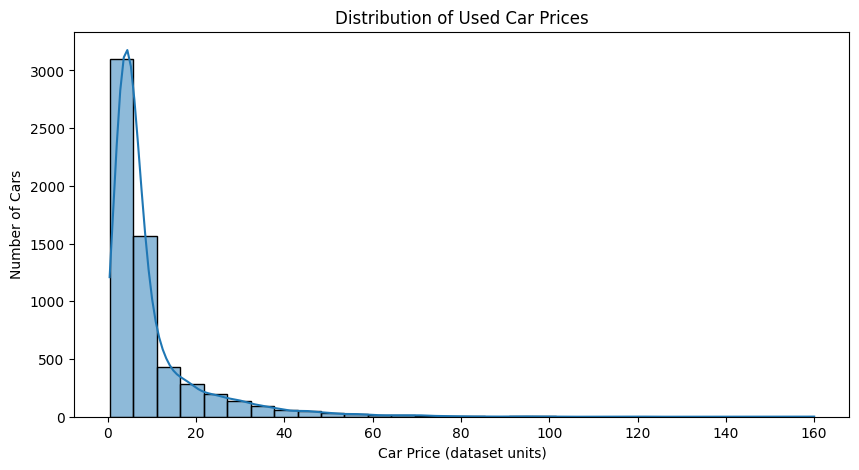

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(df['Price'], bins=30, kde=True)

plt.title('Distribution of Used Car Prices')
plt.xlabel('Car Price (dataset units)')
plt.ylabel('Number of Cars')

plt.show()

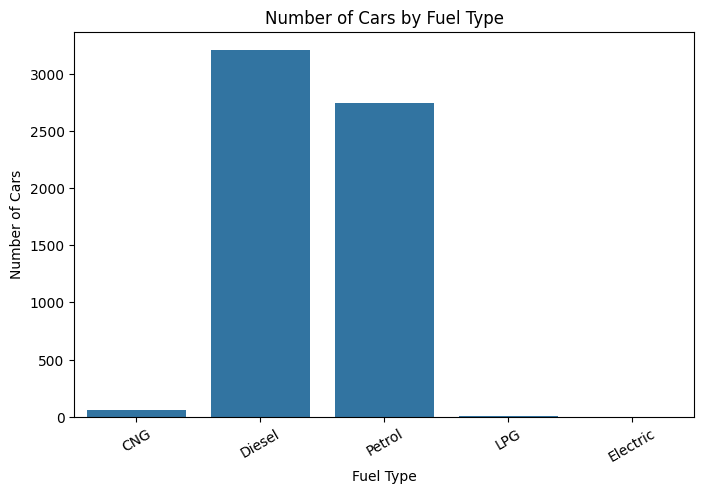

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Fuel_Type')

plt.title('Number of Cars by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Number of Cars')

plt.xticks(rotation=30)

plt.show()

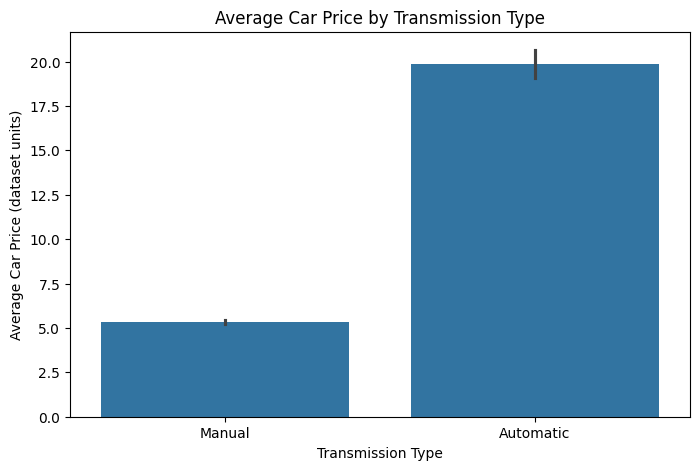

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Transmission',
    y='Price',
    estimator='mean'
)

plt.title('Average Car Price by Transmission Type')
plt.xlabel('Transmission Type')
plt.ylabel('Average Car Price (dataset units)')

plt.show()

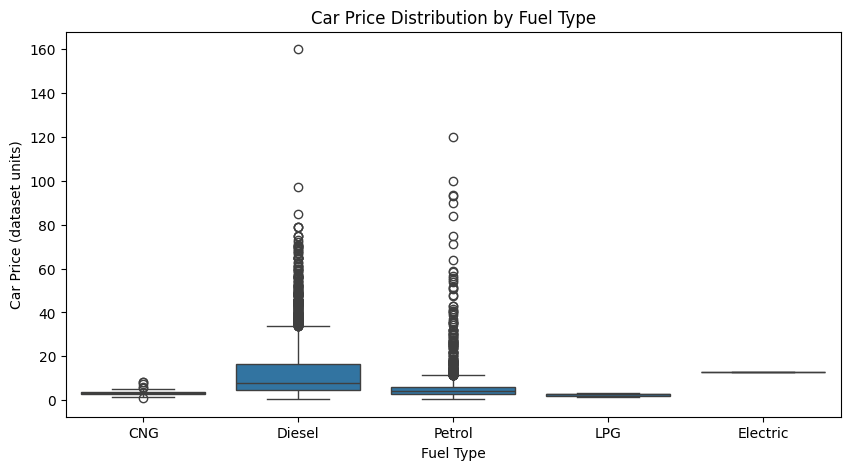

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='Fuel_Type',
    y='Price'
)

plt.title('Car Price Distribution by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Car Price (dataset units)')

plt.show()

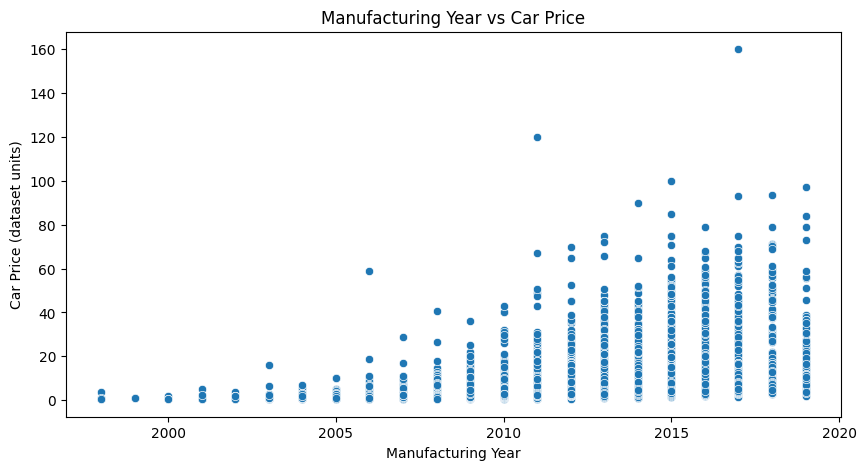

In [ ]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='Year',
    y='Price'
)

plt.title('Manufacturing Year vs Car Price')
plt.xlabel('Manufacturing Year')
plt.ylabel('Car Price (dataset units)')

plt.show()

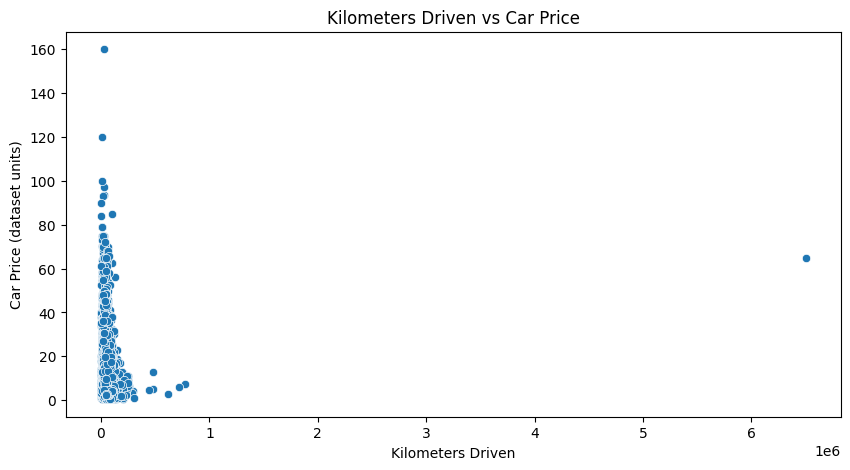

In [ ]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='Kilometers_Driven',
    y='Price'
)

plt.title('Kilometers Driven vs Car Price')
plt.xlabel('Kilometers Driven')
plt.ylabel('Car Price (dataset units)')

plt.show()

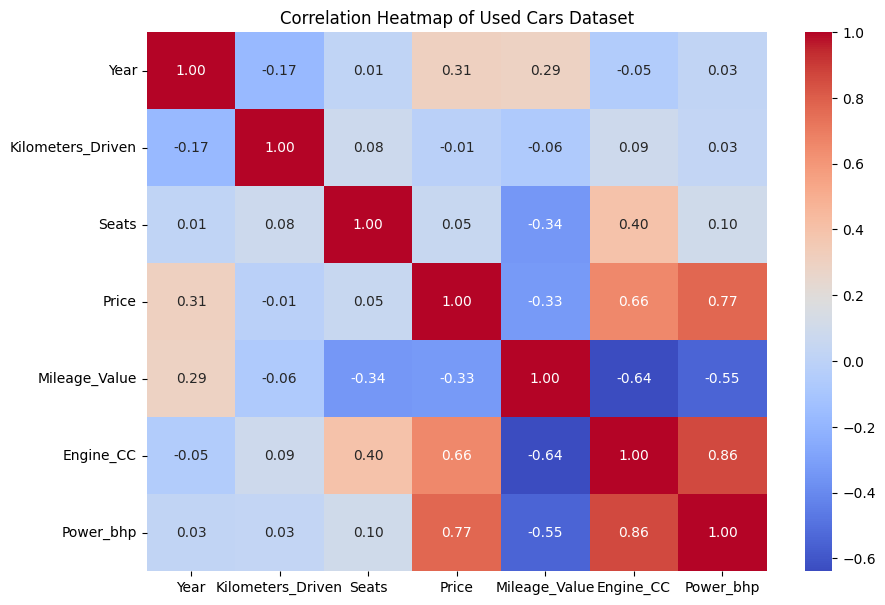

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Used Cars Dataset')

plt.show()

In [ ]:
print("Most Common Fuel Type:")

print(df['Fuel_Type'].value_counts().idxmax())

print("\nFuel Type Counts:")

print(df['Fuel_Type'].value_counts())

Most Common Fuel Type:
Diesel

Fuel Type Counts:
Fuel_Type
Diesel      3205
Petrol      2746
CNG           56
LPG           10
Electric       2
Name: count, dtype: int64


In [ ]:
print("Average Price by Fuel Type:")

print(
    df.groupby('Fuel_Type')['Price']
    .mean()
    .sort_values(ascending=False)
)

Average Price by Fuel Type:
Fuel_Type
Electric    12.875000
Diesel      12.840605
Petrol       5.701100
CNG          3.516786
LPG          2.487000
Name: Price, dtype: float64


In [ ]:
print("Average Price by Transmission:")

print(
    df.groupby('Transmission')['Price']
    .mean()
)

Average Price by Transmission:
Transmission
Automatic    19.843971
Manual        5.332703
Name: Price, dtype: float64


In [ ]:
print("Correlation with Car Price:")

print(
    df.select_dtypes(include=np.number)
    .corr()['Price']
    .sort_values(ascending=False)
)

Correlation with Car Price:
Price                1.000000
Power_bhp            0.769854
Engine_CC            0.657392
Year                 0.305327
Seats                0.053787
Kilometers_Driven   -0.011493
Mileage_Value       -0.329390
Name: Price, dtype: float64


In [ ]:
print("Top 10 Locations with Most Cars:")

print(df['Location'].value_counts().head(10))

Top 10 Locations with Most Cars:
Location
Mumbai        790
Hyderabad     742
Kochi         651
Coimbatore    636
Pune          622
Delhi         554
Kolkata       535
Chennai       494
Jaipur        413
Bangalore     358
Name: count, dtype: int64
